# Workshop 3-2: Logistic regression (class imbalance)

**Real-life problem:** Catching card fraud when almost every transaction is legitimate. Accuracy hides the failure.

**My twist:** Keep the workshop's imbalanced data and class weights (adding the weight grid the PDF describes but doesn't show), but score with precision, recall and PR-AUC. Then pick the decision threshold by business cost. Assume a missed fraud costs £100 and a false alarm costs £5 (change these).

**Done when:** A table of total cost for plain vs class-weighted logistic regression at their best thresholds, and a one-line recommendation.

*Baseline = the lecturer's workshop code (unmodified copy in `_baseline/`). Everything below the line starts as that baseline; edit it.*

---


## Part A: class imbalance with logistic regression (the lecturer's baseline)

A balanced dataset, then a 1%-minority dataset, then class weights, all scored with ROC AUC. Left as is.

Counter({np.int64(0): 5000, np.int64(1): 5000})


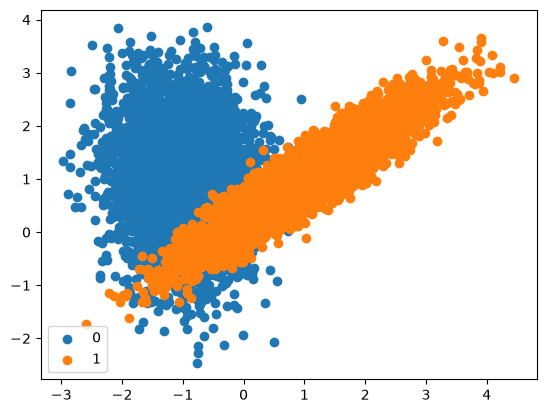

In [11]:
	# Generate and plot a synthetic balanced classification dataset
from collections import Counter
from sklearn.datasets import make_classification
from matplotlib import pyplot
from numpy import where
# define dataset
X, y = make_classification(n_samples=10000, n_features=2, n_redundant=0,
  n_clusters_per_class=1, weights=[0.5], flip_y=0, random_state=2)
# summarize class distribution
counter = Counter(y)
print(counter)
# scatter plot of examples by class label
for label, _ in counter.items():
  row_ix = where(y == label)[0]
  pyplot.scatter(X[row_ix, 0], X[row_ix, 1], label=str(label))
pyplot.legend()
pyplot.show()

In [12]:
	# fit a logistic regression model on an balanced classification dataset
from numpy import mean
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.linear_model import LogisticRegression

# define model
model = LogisticRegression(solver='lbfgs')
# define evaluation procedure
cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=1)
# evaluate model
scores = cross_val_score(model, X, y, scoring='roc_auc', cv=cv, n_jobs=-1)
# summarize performance
print('Mean ROC AUC: %.3f' % mean(scores))

Mean ROC AUC: 0.983


In [13]:
# CLASS IMBALANCE

Counter({np.int64(0): 9900, np.int64(1): 100})


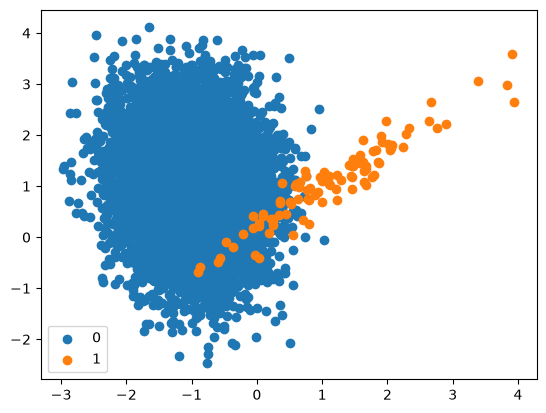

In [14]:
# Generate and plot a synthetic imbalanced classification dataset
from collections import Counter
from sklearn.datasets import make_classification
from matplotlib import pyplot
from numpy import where

# define dataset
X, y = make_classification(n_samples=10000, n_features=2, n_redundant=0,
  n_clusters_per_class=1, weights=[0.99], flip_y=0, random_state=2)
# summarize class distribution
counter = Counter(y)
print(counter)
# scatter plot of examples by class label
for label, _ in counter.items():
  row_ix = where(y == label)[0]
  pyplot.scatter(X[row_ix, 0], X[row_ix, 1], label=str(label))
pyplot.legend()
pyplot.show()

In [15]:
# fit a logistic regression model on an imbalanced classification dataset
from numpy import mean
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.linear_model import LogisticRegression

# define model
weights = {0:0.01, 1:0.99}
model = LogisticRegression(solver='lbfgs',class_weight=weights)
#model = LogisticRegression(solver='lbfgs', class_weight='balanced')
# define evaluation procedure
cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=1)
# evaluate model
scores = cross_val_score(model, X, y, scoring='roc_auc', cv=cv, n_jobs=-1)
# summarize performance
print('Mean ROC AUC: %.3f' % mean(scores))

Mean ROC AUC: 0.989


---
## Part B: real life: catching card fraud

**Problem:** about 1 transaction in 100 is fraud (the workshop's 1% data, standing in for card transactions). Each one we miss costs money; each legitimate transaction we wrongly flag costs a customer-service call. **Where should we set the alert line?**

**My cost assumptions (change them):** a missed fraud costs **£100**, a false alarm costs **£5**.

**Plan:** show why accuracy is the wrong score → compare class-weighted models → pick the alert threshold by cost → check how it changes if the £ figures change.

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, average_precision_score, accuracy_score, precision_score, recall_score

# the workshop's imbalanced data: 10,000 transactions, 1% fraud
X, y = make_classification(n_samples=10000, n_features=2, n_redundant=0,
                           n_clusters_per_class=1, weights=[0.99], flip_y=0, random_state=2)

COST_MISS = 100        # £ lost per fraud we fail to flag
COST_FALSE_ALARM = 5   # £ per legitimate transaction we wrongly flag
thresholds = np.round(np.arange(0.01, 1.0, 0.01), 2)

def total_cost(y_true, p, t, miss=COST_MISS, alarm=COST_FALSE_ALARM):
    flagged = p >= t
    return miss * ((~flagged) & (y_true == 1)).sum() + alarm * (flagged & (y_true == 0)).sum()

print(f'{y.sum()} frauds in {len(y)} transactions')
print(f'cost of doing nothing:       £{COST_MISS * y.sum():,}')
print(f'cost of flagging everything: £{COST_FALSE_ALARM * (y == 0).sum():,}')

100 frauds in 10000 transactions
cost of doing nothing:       £10,000
cost of flagging everything: £49,500


### 1. Accuracy hides the failure
Each model predicts every transaction it did **not** train on (10-fold cross-validation), so the numbers are not flattered. The class weights are the workshop's idea: `balanced`, the workshop's `{0: 0.01, 1: 0.99}`, and a small grid of weights on the fraud class (the "grid search" the PDF describes). Scores below use the default alert line of 0.5.

In [17]:
models = {
    'plain':                 dict(),
    'balanced':              dict(class_weight='balanced'),
    'workshop {0:.01,1:.99}': dict(class_weight={0: 0.01, 1: 0.99}),
}
for w in (2, 5, 10, 25, 50):                                  # grid over the fraud-class weight
    models[f'fraud weight {w}'] = dict(class_weight={0: 1, 1: w})

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=1)
proba = {name: cross_val_predict(LogisticRegression(solver='lbfgs', **kw), X, y, cv=cv, method='predict_proba')[:, 1]
         for name, kw in models.items()}

rows = []
for name, p in proba.items():
    rows.append({'model': name,
                 'accuracy': accuracy_score(y, p >= 0.5),
                 'frauds caught (recall)': recall_score(y, p >= 0.5),
                 'alerts that are real (precision)': precision_score(y, p >= 0.5, zero_division=0),
                 'ROC AUC': roc_auc_score(y, p),
                 'PR-AUC': average_precision_score(y, p),
                 'cost at 0.5 (£)': total_cost(y, p, 0.5)})
at_half = pd.DataFrame(rows).set_index('model')
at_half.round(3)

,accuracy,frauds caught (recall),alerts that are real (precision),ROC AUC,PR-AUC,cost at 0.5 (£)
model,,,,,,
plain,0.996,0.60,0.952,0.985,0.803,4015
balanced,0.941,0.95,0.140,0.989,0.682,3410
"workshop {0:.01,1:.99}",0.942,0.94,0.141,0.989,0.736,3470
fraud weight 2,0.995,0.67,0.838,0.986,0.800,3365
fraud weight 5,0.994,0.75,0.658,0.987,0.794,2695
fraud weight 10,0.989,0.78,0.476,0.988,0.786,2630
fraud weight 25,0.977,0.87,0.285,0.988,0.764,2390
fraud weight 50,0.963,0.92,0.201,0.989,0.732,2625


- **Accuracy ranks the models backwards.** Plain logistic regression has the best accuracy (about 99.6%) yet catches only about 60% of the fraud. `balanced` has *worse* accuracy (94%) but catches about 95%.
- **ROC AUC barely moves** (0.985 to 0.989), so it hides the difference too.
- **Money is the honest score.** Doing nothing costs £10,000; at the default 0.5 line every model still loses £2,400 to £4,000. The next step is to stop using 0.5.

### 2. Pick the alert line by cost
For each model, the total cost at every possible threshold. A model flags a transaction when its fraud probability is at least the threshold.

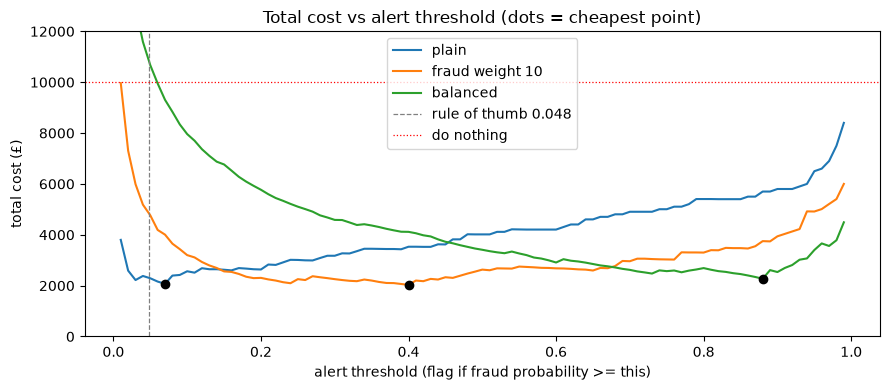

In [18]:
curves = {name: [total_cost(y, p, t) for t in thresholds] for name, p in proba.items()}
theory_t = COST_FALSE_ALARM / (COST_FALSE_ALARM + COST_MISS)    # rule of thumb for a calibrated model

fig, ax = plt.subplots(figsize=(9, 4))
for name in ['plain', 'fraud weight 10', 'balanced']:
    c = np.array(curves[name])
    ax.plot(thresholds, c, label=name)
    ax.plot(thresholds[c.argmin()], c.min(), 'ko')
ax.axvline(theory_t, color='grey', ls='--', lw=0.9, label=f'rule of thumb {theory_t:.3f}')
ax.axhline(COST_MISS * y.sum(), color='r', ls=':', lw=0.9, label='do nothing')
ax.set_ylim(0, 12000)
ax.set_xlabel('alert threshold (flag if fraud probability >= this)'); ax.set_ylabel('total cost (£)')
ax.set_title('Total cost vs alert threshold (dots = cheapest point)')
ax.legend(); plt.tight_layout(); plt.show()

Every model has a cheapest point, but at very different thresholds: plain logistic regression is cheapest near **0.07**, `balanced` near **0.9**. Class weights do not make the model smarter; they just move the line.

Picking the cheapest point on the same data it is measured on is slightly flattering, so the next cell is more honest: choose the threshold on one random half of the transactions and score it on the other half (and vice versa), repeated over 20 different splits.

In [19]:
def honest_cost(p, miss=COST_MISS, alarm=COST_FALSE_ALARM, repeats=20):
    totals = []
    for seed in range(repeats):
        total = 0
        for pick, score in StratifiedKFold(2, shuffle=True, random_state=seed).split(p, y):
            t = thresholds[np.argmin([total_cost(y[pick], p[pick], t, miss, alarm) for t in thresholds])]
            total += total_cost(y[score], p[score], t, miss, alarm)
        totals.append(total)
    return np.mean(totals), np.std(totals)

rows = []
for name, p in proba.items():
    c = np.array(curves[name]); mean, sd = honest_cost(p)
    rows.append({'model': name,
                 'cost at 0.5 (£)': total_cost(y, p, 0.5),
                 'cheapest threshold': thresholds[c.argmin()],
                 'honest cost (£)': round(mean),
                 'spread across splits (£)': round(sd),
                 f'cost at rule-of-thumb {theory_t:.3f} (£)': total_cost(y, p, theory_t)})
costs = pd.DataFrame(rows).set_index('model')
costs

,cost at 0.5 (£),cheapest threshold,honest cost (£),spread across splits (£),cost at rule-of-thumb 0.048 (£)
model,,,,,
plain,4015,0.07,2311,270,2310
balanced,3410,0.88,2448,221,10900
"workshop {0:.01,1:.99}",3470,0.79,2477,290,20015
fraud weight 2,3365,0.13,2310,249,2400
fraud weight 5,2695,0.27,2391,209,3470
fraud weight 10,2630,0.40,2327,254,4865
fraud weight 25,2390,0.61,2480,295,7020
fraud weight 50,2625,0.78,2533,295,8960


- **Tuning the line is where the money is.** Plain logistic regression goes from about £4,000 (at 0.5) to about £2,300, a 42% cut, and about 77% below doing nothing (£10,000). No new model was needed.
- **After tuning, the models are the same.** Every variant lands between about £2,300 and £2,550, a gap smaller than the split-to-split spread (about £200 to £300). Class weights bought nothing once the threshold was set from the costs.
- **The rule of thumb works for the plain model only.** Flagging at `false-alarm cost / (false-alarm cost + miss cost)` = 5 / 105 ≈ 4.8% gives plain logistic regression nearly the best cost with no searching. For the heavily weighted models it is a disaster (`balanced` £10,900, the workshop's weights £20,015, and the more weight the worse), because class weights distort their probabilities so they are no longer real fraud chances.

### 3. What if the £ figures are wrong?
The threshold depends entirely on the two cost assumptions, which in a real company come from finance or risk, not from the data scientist. For plain logistic regression at the rule-of-thumb threshold:

In [20]:
p = proba['plain']
rows = []
for miss in (20, 50, 100, 500, 1000):
    t = COST_FALSE_ALARM / (COST_FALSE_ALARM + miss)
    flagged = p >= t
    rows.append({'missed fraud costs (£)': miss,
                 'alert threshold': round(t, 3),
                 'transactions flagged (%)': round(flagged.mean() * 100, 1),
                 'alerts that are real fraud (%)': round(precision_score(y, flagged) * 100),
                 'frauds caught (%)': round(recall_score(y, flagged) * 100),
                 'total cost (£)': total_cost(y, p, t, miss=miss),
                 'doing nothing (£)': miss * y.sum()})
pd.DataFrame(rows).set_index('missed fraud costs (£)')

,alert threshold,transactions flagged (%),alerts that are real fraud (%),frauds caught (%),total cost (£),doing nothing (£)
missed fraud costs (£),,,,,,
20,0.200,1.0,74,75,635,2000
50,0.091,1.6,49,80,1415,5000
100,0.048,2.5,34,85,2310,10000
500,0.010,7.4,13,94,6215,50000
1000,0.005,11.2,8,95,10125,100000


### Recommendation

**Use plain logistic regression and set the alert line from the costs: flag a transaction when its fraud probability is at least `false-alarm cost / (false-alarm cost + miss cost)`, about 5% here.** On 10,000 transactions that costs about £2,300 instead of £10,000 for doing nothing. The team would see about 2.5% of transactions flagged; a third of those alerts (34%) are real fraud, and 85% of all fraud is caught. Skip class weights unless you need them for another reason, and **re-set the line whenever the £ figures change**: the more a missed fraud costs, the lower the line and the more alerts the team must handle. In the last table, going from £20 to £1,000 per missed fraud raises the share of transactions flagged from 1% to 11%, while the share of alerts that are real falls from 74% to 8%.

**Caveats:** two made-up features and 100 frauds, so the exact numbers are illustrative. The £5 and £100 are my assumptions. Real card fraud is nearer 0.1% than 1%, which makes alerts far less likely to be real fraud. And fraudsters adapt, so the model and the line need re-checking over time.